# Glacier recovery experiment

Can we recover unavailable fragment predictions while preserving current behavior?

This notebook is an **isolated pilot**. It uses a frozen copy of the candidate definitions from `Experiment_1.ipynb`, the same pinned pretrained weights, and the exact 84 candidates from MS2 scan 297. It does not modify the working notebook or production adapter. Recovered spectra are experimental; chemical validity and model execution do not establish accuracy.

**Read the saved results below immediately.** Set `RUN_FULL_AUDIT = True` to rerun preparation and model forwards for all 84 candidates. Use the **MAGMA / Glacier (Python 3.10)** kernel; the ordinary system Python lacks this project's model dependencies.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "recovery_lab" / "pilot_candidates.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from recovery_lab.experiment import (
    LAB, load_pilot, load_model, candidate_from_pilot,
    prepare_candidate, predict_candidate, run_pilot, verify_production_files,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Python:", sys.executable)
print("Isolated experiment:", LAB)
print("Production source files matching snapshot:", verify_production_files())

## Why the original adapter stops

The current adapter enumerates **closed-shell +1 ions** while fixing the inherited MAGMa heavy-atom graph, bond orders, aromatic labels, elemental formula, and precursor mass.

* **74 candidates:** their formulas imply an odd number of electrons at charge +1. No closed-shell assignment can satisfy that formula, regardless of a larger `max_states` value.
* **One C6H5+ candidate:** RDKit sanitizes the phenyl cation to `[C+]1=CC=CC=C1`. Its inherited aromatic flags change, so the exact-graph validator rejects an otherwise valid closed-shell ion.
* **Nine candidates:** already supported and retained through the existing input and postprocessing path.

These are adapter representation limits, not missing checkpoint weights. The pilot below retains candidate ordering and never uses an observed MS3 spectrum to choose a representation.

In [2]:
pilot = load_pilot()
original = pd.DataFrame([
    {"bag": r["bag_index"], "candidate": r["candidate_index"],
     "m/z": r["stripped"]["precursor_mz"],
     "baseline result": r["baseline_reason"] or "available"}
    for r in pilot["candidates"]
])
display(original.groupby(["m/z", "baseline result"]).size().rename("candidates").to_frame())
print("Source:", pilot["source_path"])
print("Parent scan:", pilot["parent_scan"], "| model CE:", pilot["model_collision_energy"])
print("CE is passed through as in Experiment_1; no conversion or MS3 energy calibration is assumed.")

candidates
m/z        baseline result                                             
77.039901  available                                                  3
           no_valid_state_in_declared_domain                          1
184.087005 available                                                  1
185.070999 available                                                  2
203.036804 odd_electron_formula_outside_closed_shell_domain           2
203.045761 available                                                  2
315.102142 odd_electron_formula_outside_closed_shell_domain          72
356.106903 available                                                  1

Source: msnlib/20241003_enamdisc_pos_msn.json
Parent scan: 297 | model CE: 30.0
CE is passed through as in Experiment_1; no conversion or MS3 energy calibration is assumed.


## Recovery rules

| Path | What changes | What stays fixed | Status |
|---|---|---|---|
| Existing supported candidate | Nothing | Inputs, state selection, weights, spectrum processing | Regression checked |
| Aromatic recovery | Inherited aromatic labels may sanitize to single/double Kekulé bonds | Connectivity, nonaromatic bond orders, formula, +1 charge, mass | Experimental representation repair |
| Odd-electron recovery | Use an exact-formula **neutral closed-shell reference** with the native `[M]+` adduct | Heavy graph, bond/aromatic labels, total H/formula, ion mass | Experimental model representation |

The neutral reference is **not claimed to be the ionic fragment itself**. `[M]+` supplies the +1 ionization convention without adding a proton. Local H/charge features can differ. Neither helper invents hydrogens to force an answer. Search and state-count limits remain bounded, and all changes and retained SMILES are recorded.

The dispatcher first tries the original adapter; fallback is disabled unless `allow_experimental=True`. See [`experiment.py`](recovery_lab/experiment.py), [`neutral_reference.py`](recovery_lab/neutral_reference.py), and [`aromatic_recovery.py`](recovery_lab/aromatic_recovery.py).

In [3]:
RUN_FULL_AUDIT = False
if RUN_FULL_AUDIT or not (LAB / "results.json").exists():
    report = run_pilot()  # Writes only recovery_lab/results.json; predicts every available candidate.
else:
    report = json.loads((LAB / "results.json").read_text())
summary = report["summary"]
rows = pd.DataFrame(report["candidates"])
display(pd.DataFrame([
    {"route": route, "available candidates": count}
    for route, count in summary["available_by_route"].items()
]))
print(f"Coverage: {summary['baseline_available']}/{summary['total_candidates']} baseline; "
      f"{summary['combined_available']}/{summary['total_candidates']} with experimental recovery.")
print("All candidates forwarded:", summary["all_available_candidates_forward_tested"])
print("All outputs finite, nonempty, normalized:", summary["all_forward_outputs_finite_nonempty_normalized"])
print("Preparation time in recorded run:", round(summary["preparation_seconds"], 2), "seconds")

,route,available candidates
0,baseline,9
1,experimental_aromatic_kekule_reference,1
2,neutral_reference_[M]+,74


Coverage: 9/84 baseline; 84/84 with experimental recovery.
All candidates forwarded: True
All outputs finite, nonempty, normalized: True
Preparation time in recorded run: 18.87 seconds


In [4]:
regression = pd.DataFrame(report["baseline_regression"])
assert len(regression) == 9 and regression["array_equal"].all()
assert all(r["input_unchanged"] for r in report["candidates"])
assert not summary["recovered_accuracy_validated"]
display(regression[["array_equal", "peak_count"]])
print("All nine existing peak arrays are exactly equal to FragmentGlacierAdapter.predict().")
print("All 84 original candidate records stayed unchanged.")
print("Checkpoint SHA-256:", summary["checkpoint"]["checkpoint_sha256"])
print("Upstream commit:", summary["checkpoint"]["ms_pred_commit"])

,array_equal,peak_count
0,True,30
1,True,30
2,True,30
3,True,156
4,True,151
5,True,139
6,True,178
7,True,212
8,True,113


All nine existing peak arrays are exactly equal to FragmentGlacierAdapter.predict().
All 84 original candidate records stayed unchanged.
Checkpoint SHA-256: 5a47cecca707d3abd5a49c7dbac99d100aa2a586d5d4f848f1e8e35140d7db11
Upstream commit: 67ba0f202305d4bed3134991dd4562fe1edb1763


## Visual inspection

The gallery shows the first retained representation for each selected candidate above the **mean prediction over all retained states**. Neutral references are labelled explicitly. This is a visualization of model outputs, not a match to measured MS3 or a confirmed structural assignment.

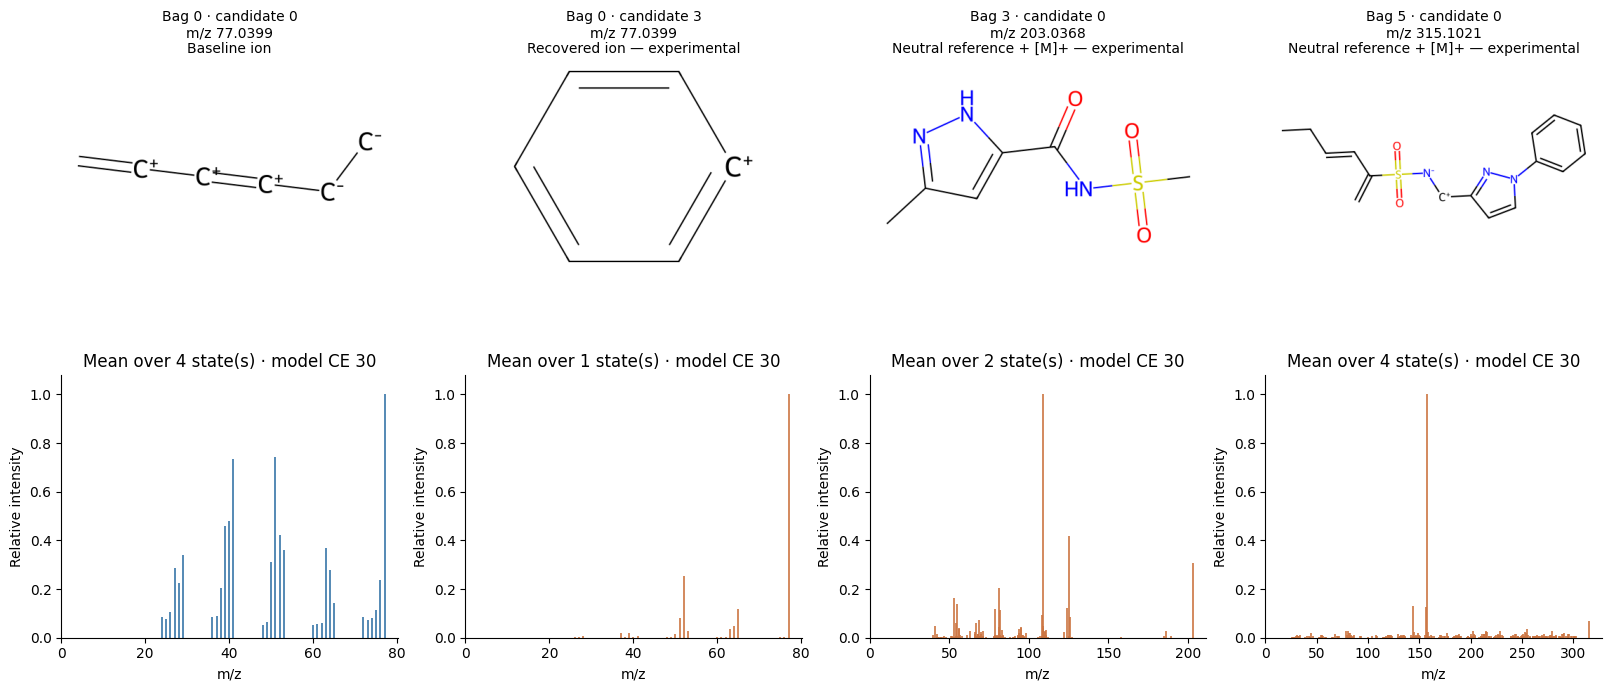

In [5]:
from rdkit import Chem
from rdkit.Chem import Draw

forward = report["forward_samples"]
selected = [next(p for p in forward if p["route"] == "baseline"),
            next(p for p in forward if "aromatic" in p["route"]),
            next(p for p in forward if "neutral_reference" in p["route"] and p["bag_index"] == 3),
            next(p for p in forward if "neutral_reference" in p["route"] and p["bag_index"] == 5)]

fig, axes = plt.subplots(2, len(selected), figsize=(16, 7), squeeze=False,
                         gridspec_kw={"height_ratios": [1.35, 1]}, layout="constrained")
for col, item in enumerate(selected):
    state = item["states"][0]
    smiles = state.get("ionic_smiles", state.get("reference_smiles"))
    mol = Chem.MolFromSmiles(smiles)
    axes[0, col].imshow(Draw.MolToImage(mol, size=(480, 300)))
    axes[0, col].axis("off")
    label = ("Baseline ion" if item["route"] == "baseline" else
             "Recovered ion — experimental" if "aromatic" in item["route"] else
             "Neutral reference + [M]+ — experimental")
    axes[0, col].set_title(f"Bag {item['bag_index']} · candidate {item['candidate_index']}\n"
                           f"m/z {item['mz']:.4f}\n{label}", fontsize=10)
    peaks = np.asarray(item["spectrum"])
    axes[1, col].vlines(peaks[:, 0], 0, peaks[:, 1] / peaks[:, 1].max(),
                        color="#cc7542" if item["experimental"] else "#3776a8", linewidth=1.2)
    axes[1, col].set(xlim=(0, item["mz"] * 1.04), ylim=(0, 1.08),
                     xlabel="m/z", ylabel="Relative intensity",
                     title=f"Mean over {len(item['states'])} state(s) · model CE 30")
    axes[1, col].spines[["top", "right"]].set_visible(False)
fig.savefig(LAB / "recovery_gallery.png", dpi=160, bbox_inches="tight")
plt.show()

## How strong are the recovered representations?

Full availability is a permissive experimental result. Of the 74 neutral references, **17 need no formal charges; 57 need separated positive and negative formal charges** (net zero). Those charge-separated structures satisfy the enumerator's rules but are not evidence for likely physical fragment states. The gallery deliberately exposes the represented structures.

Across all candidates, **40 searches hit the 512-state chemical cap**, and **64 preparations cap the retained features at four states**. This is a bounded selection, not exhaustive enumeration or an uncertainty estimate. Raising these limits does not resolve the original odd-electron parity restriction.

A more conservative inspection subset keeps the nine baseline cases, the one aromatic repair, and the 17 neutral references without separated charges: **27 candidates in total**. Even this subset does not establish prediction accuracy. No recovery tier should be promoted on coverage alone.

In [6]:
neutral_rows = [r for r in report["candidates"] if r["route"] == "neutral_reference_[M]+"]
charge_counts = pd.Series([r["metadata"]["minimum_abs_charge"] for r in neutral_rows],
                          name="sum of absolute formal charges").value_counts().sort_index()
display(charge_counts.rename("neutral-reference candidates").to_frame())
conservative_ids = {r["candidate_id"] for r in report["candidates"]
                    if r["available"] and (r["route"] != "neutral_reference_[M]+"
                       or r["metadata"]["minimum_abs_charge"] == 0)}
print("Conservative inspection subset:", len(conservative_ids), "of", len(rows))
print("Chemical-cap stops:", sum(r["metadata"]["stop_reason"] == "chemical_cap" for r in report["candidates"]))
print("Four-state selection cap:", sum(bool(r["metadata"].get("feature_selection_capped")) for r in report["candidates"]))

,neutral-reference candidates
sum of absolute formal charges,
0,17
2,17
4,21
6,19


Conservative inspection subset: 27 of 84
Chemical-cap stops: 40
Four-state selection cap: 64


## Does this preserve prediction performance?

**For the nine already supported candidates:** yes for the observed behavior in this pilot. All nine full peak arrays compare exactly equal, with unchanged weights, state selection, and postprocessing. This is not a general accuracy benchmark.

**For the 75 newly supported candidates:** accuracy remains unvalidated. All now produce finite, normalized spectra, but changed molecular representations can change prediction quality. No weight retraining occurred. Recovering candidates also costs additional enumeration and forward time; unchanged prediction behavior does not mean zero runtime overhead.

The local MSG label file contains 119,029 `[M+H]+` records and no `[M]+` records. This describes the inspected labels, not proof of the checkpoint's entire training history. It gives no basis for assuming native vocabulary support means validated radical-ion accuracy. The baseline direct ionic route also uses `[M]+`.

Below are the linked MS3 observations. The recovered bags have none, so this example cannot directly validate the new predictions against observed children. Even a bag with MS3 is a spectrum for the isolated m/z, not proof that every candidate in that bag is correct.

In [7]:
observations = pd.DataFrame(pilot["bag_observations"])
recovered_bags = set(rows.loc[rows["experimental"] & rows["available"], "bag_index"])
observations["has recovered candidates"] = observations["bag_index"].isin(recovered_bags)
display(observations)
print("Observed children in recovered bags:",
      sum(len(r["ms3_scans"]) for r in pilot["bag_observations"]
          if r["bag_index"] in recovered_bags))
print("Inspected local MSG label adducts:", summary["local_msg_label_adduct_counts"])

,bag_index,mz,ms3_scans,ms3_collision_energies,has recovered candidates
0,0,77.039901,[],[],True
1,1,184.087005,"[307, 306, 305]","[60.0, 40.0, 20.0]",False
2,2,185.070999,"[304, 303, 302]","[60.0, 40.0, 20.0]",False
3,3,203.036804,[],[],True
4,4,203.045761,[],[],False
5,5,315.102142,[],[],True
6,6,356.106903,[],[],False


Observed children in recovered bags: 0
Inspected local MSG label adducts: {'[M+H]+': 119029}


## Try one candidate in this sandbox

`predict_candidate()` returns `spectrum`, `route`, `experimental`, `states`, the original failure reason, and the preparation audit. The spectrum is a repository `Spectrum`; call `.as_array()` for `(m/z, intensity)` pairs. If recovery is disabled and the adapter cannot represent a candidate, `spectrum` is `None`.

The following cell is opt-in so simply opening or executing this results notebook does not load another model into memory while the main notebook is running. It does not alter `Experiment_1.ipynb`.

In [8]:
TRY_ONE = False
if TRY_ONE:
    model = load_model()
    source = next(r for r in pilot["candidates"]
                  if r["baseline_reason"] == "odd_electron_formula_outside_closed_shell_domain")
    candidate = candidate_from_pilot(source)
    result = predict_candidate(model, candidate, collision_energy=30,
                               allow_experimental=True)
    print(result["route"], "experimental:", result["experimental"])
    display(result["spectrum"].as_array() if result["spectrum"] is not None else result["reason"])
else:
    print("Saved results shown above; set TRY_ONE=True to run a new prediction.")

Saved results shown above; set TRY_ONE=True to run a new prediction.


## What is ready to use

Keep successful baseline predictions unchanged. Treat aromatic recovery as the narrower repair worth validating first; keep the neutral-reference route experimental until checked on held-out, matched-energy fragment/MS3 data with trustworthy assignments. The current result is **full prediction availability for this pilot, with exact regression preservation of existing outputs**, not demonstrated accuracy parity for recovered fragments.

Independent chemical-invariant tests live in [`recovery_lab/test_recovery.py`](recovery_lab/test_recovery.py): 22 passed. They check formula/H/mass, native `[M]+` precursor semantics, graph constraints, invalid inputs, and nonmutation. The full model experiment additionally checks every candidate's output and all nine baseline regressions.

Provenance: [`pilot_candidates.json`](recovery_lab/pilot_candidates.json), [`results.json`](recovery_lab/results.json), and [`snapshot_manifest.json`](recovery_lab/snapshot_manifest.json). Only frozen definition cells are copied in `baseline_snapshot.py`; rerunning this lab does not read or execute the user's changing working notebook.